In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.affinity import scale
from pyproj import CRS

from IPython.display import display
from io import StringIO

In [2]:
# Reading ASCII grid from data
def read_ascii_grid(path):
    # Header is loaded separately
    header = {}
    with open(path, "r") as f:
        for _ in range(6):
            key, value = f.readline().split()
            header[key] = float(value) if "." in value else int(value)

    ncols = header["NCOLS"]
    nrows = header["NROWS"]
    nodata = header["NODATA_VALUE"]

    # Remaining part of data
    data = pd.read_csv(
        path,
        sep=r'\s+',
        skiprows=6,
        header=None
    )

    raster = data.values.reshape((nrows, ncols))
    raster = raster.astype(np.float32)
    raster[raster == nodata] = np.nan

    return raster, header

# Normalization of RGB bands
def normalize(band):
    minv = np.nanmin(band)
    maxv = np.nanmax(band)
    return (band - minv) / (maxv - minv)    

In [3]:
# Load
band1, h1 = read_ascii_grid("kanal_1.dat")
band2, h2 = read_ascii_grid("kanal_2.dat")
band3, h3 = read_ascii_grid("kanal_3.dat")

rgb = np.dstack((
    normalize(band1),
    normalize(band2),
    normalize(band3)
))

<a id="original-image"></a>

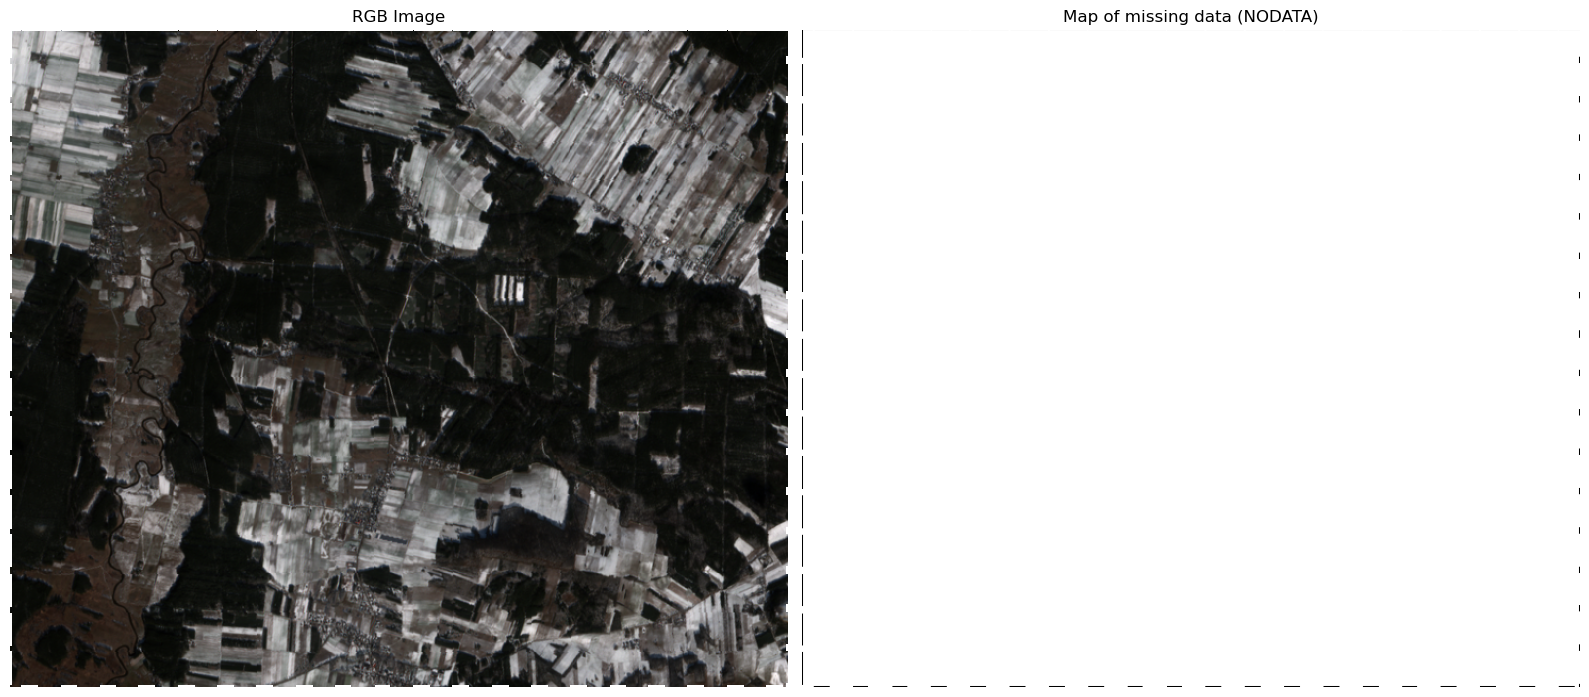

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Original RGB Image
axes[0].imshow(rgb)
axes[0].set_title("RGB Image")
axes[0].axis("off")

# Missing data
missing_mask = np.isnan(rgb).any(axis=2)
axes[1].imshow(~missing_mask, cmap='gray')
axes[1].set_title("Map of missing data (NODATA)")
axes[1].axis("off")



plt.tight_layout()
plt.show()

# Grid Search

In [5]:
# Data preparations for KMeans
mask = ~np.isnan(rgb).any(axis=2)
pixels = rgb[mask]

In [6]:
cluster_range = range(2, 11)

inertia_list = []

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(pixels)
    inertia_list.append(kmeans.inertia_)

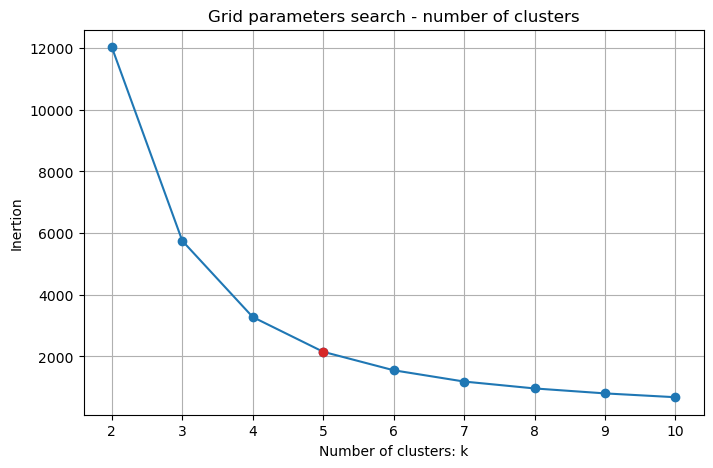

In [7]:
plt.figure(figsize=(8,5))
plt.plot(cluster_range, inertia_list, 'o-', color='tab:blue')
plt.plot(5, inertia_list[3], 'o', color='tab:red')
plt.xlabel("Number of clusters: k")
plt.ylabel("Inertion")
plt.title("Grid parameters search - number of clusters")
plt.grid(True)
plt.show()

# Modelu KMeans section, selected k=5

In [8]:
n_clusters = 5

In [9]:
# Learning phase
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
labels = kmeans.fit_predict(pixels)

In [10]:
# Average RGB
mask = ~np.isnan(rgb).any(axis=2)
original_mean = rgb[mask].mean(axis=0)

cluster_means = []
for i in range(n_clusters):
    mean_rgb = pixels[labels == i].mean(axis=0)
    cluster_means.append(mean_rgb)
cluster_means = np.array(cluster_means)

# Cluster marked as the one containing snow was the brigthest one
snow_cluster = np.argmax(cluster_means.mean(axis=1))
print(f"Snow cluster: {snow_cluster}")

Snow cluster: 3


<a id="grid-image"></a>

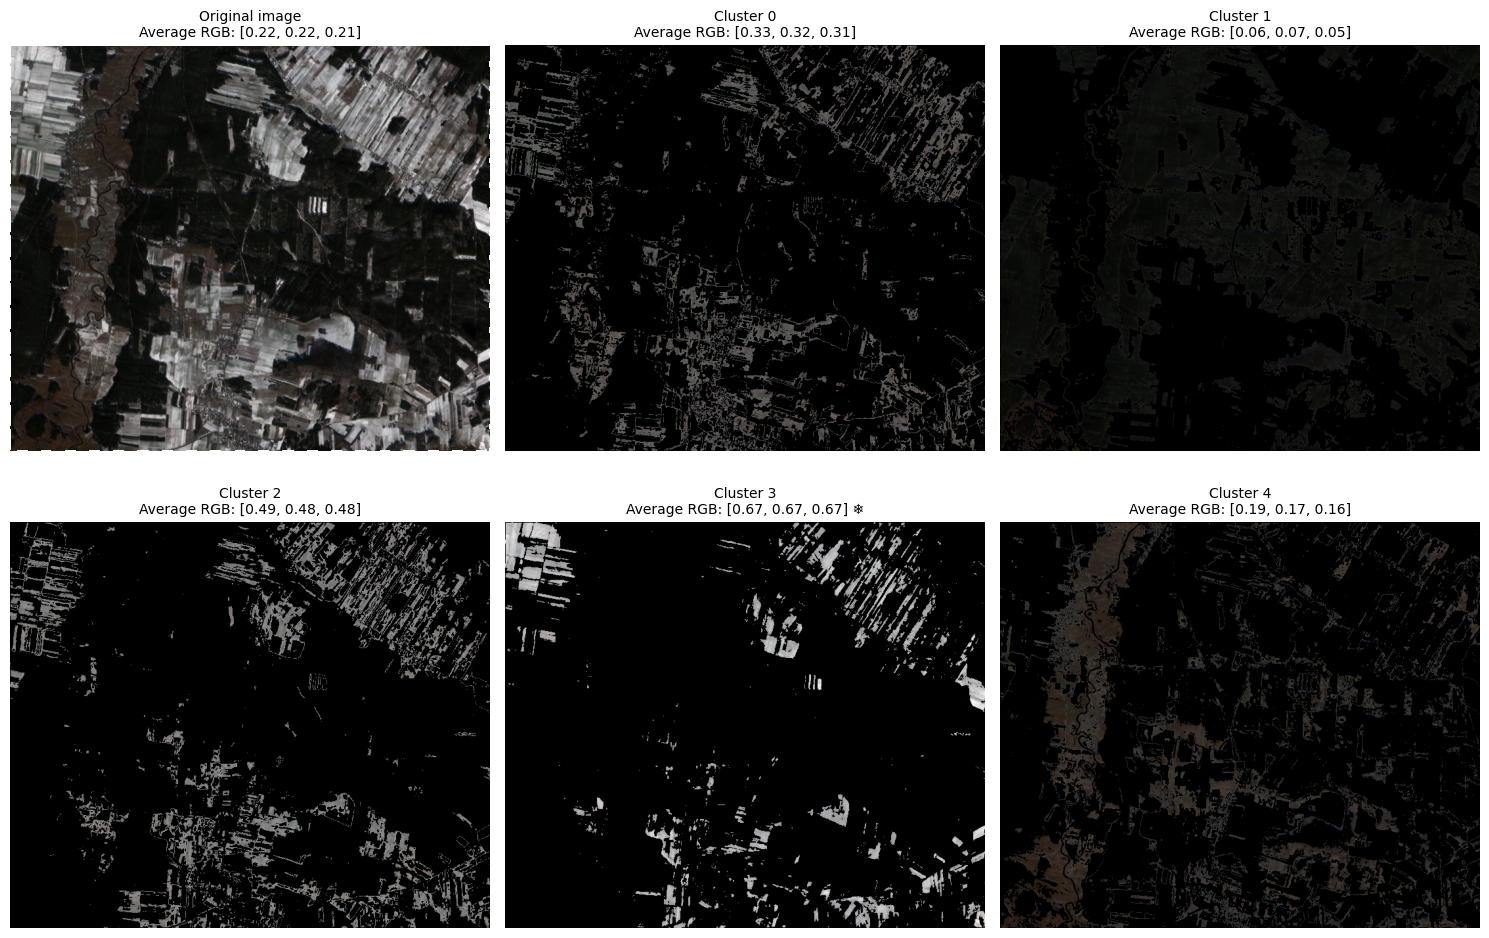

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

# Original image
orig_mean_str = ", ".join(f"{v:.2f}" for v in original_mean)
axes[0].imshow(rgb)
axes[0].set_title(f"Original image\nAverage RGB: [{orig_mean_str}]", fontsize=10)
axes[0].axis("off")

# Clusters 0-4
label_img = np.full((rgb.shape[0], rgb.shape[1]), -1)
mask = ~np.isnan(rgb).any(axis=2)
label_img[mask] = labels
for i in range(n_clusters):
    overlay = rgb.copy()
    overlay[label_img != i] = 0
    
    mean_str = ", ".join(f"{v:.2f}" for v in cluster_means[i])
    title = f"Cluster {i}\nAverage RGB: [{mean_str}]"
    
    if i == snow_cluster:
        title += " ❄️"
    
    axes[i+1].imshow(overlay)
    axes[i+1].set_title(title, fontsize=10)
    axes[i+1].axis("off")

plt.tight_layout()
plt.show()

In [12]:
PIXEL_AREA_M2 = 100  # 1 pixel = 100 m²

records = []

total_area = mask.sum()
for i in range(n_clusters):
    cluster_pixels = pixels[labels == i]
    
    mean_rgb = cluster_pixels.mean(axis=0)
    brightness = mean_rgb.mean()
    area_px = cluster_pixels.shape[0]
    
    records.append({
        "Object": f"Cluster {i}",
        "R": mean_rgb[0],
        "G": mean_rgb[1],
        "B": mean_rgb[2],
        "Brightness": brightness,
        "Area_px": area_px,
        "Area_km2": area_px * PIXEL_AREA_M2 / 10**6,
        "Participation_%": 100 * area_px / total_area
    })

df_clusters = pd.DataFrame(records)
df_clusters = df_clusters.sort_values("Brightness", ascending=False)
df_clusters["Cumulative_Participation_%"] = df_clusters["Participation_%"].cumsum()

# Appending the line with the original image
orig_pixels = rgb[mask]
orig_mean_rgb = orig_pixels.mean(axis=0)
orig_brightness = orig_mean_rgb.mean()
orig_area_px = orig_pixels.shape[0]

df_original = pd.DataFrame([{
    "Object": "Original",
    "R": orig_mean_rgb[0],
    "G": orig_mean_rgb[1],
    "B": orig_mean_rgb[2],
    "Brightness": orig_brightness,
    "Area_px": orig_area_px,
    "Area_km2":orig_area_px * PIXEL_AREA_M2 / 10**6,
    "Participation_%": 100.0
}])

df = pd.concat([df_clusters, df_original], ignore_index=True)
df[["R", "G", "B", "Brigthness", "Participation_%", "Cumulative_Participation_%"]] = df[["R", "G", "B", "Brightness", "Participation_%", "Cumulative_Participation_%"]].round(2)

<a id="area-table"></a>

In [13]:
display(df[["Object", "Brigthness", "Area_km2", "Participation_%", "Cumulative_Participation_%"]])

,Object,Brigthness,Area_km2,Participation_%,Cumulative_Participation_%
0,Cluster 3,0.67,3.3808,7.51,7.51
1,Cluster 2,0.48,5.3594,11.91,19.42
2,Cluster 0,0.32,6.3352,14.07,33.49
3,Cluster 4,0.17,9.8445,21.87,55.36
4,Cluster 1,0.06,20.0953,44.64,100.00
5,Original,0.22,45.0152,100.00,NaN


# Mapping of the plot 261301_2.0021

In [14]:
# Data comes from geoportal.gov.pl; plot 261301_2.0021
y = [349773.428662604, 349763.537808885, 349732.203277158, 349715.109327359, 349700.821491691, 349690.484153436, 349682.052056826, 349696.58898302, 349701.719598615, 349708.857843835, 349709.977539471, 349721.062498052, 349721.293357636, 349723.220534829, 349729.307438706, 349743.994654551, 349756.659132284, 349759.943127086, 349760.98406535, 349763.244800951, 349766.39629486, 349775.466760636, 349784.665017914, 349786.44489144, 349794.406412611, 349803.059682745, 349812.89284578, 349815.921978506, 349832.306547885, 349832.451485915, 349844.638347914, 349853.398029051, 349867.174090605, 349871.717899609, 349888.844698302, 349901.408373322, 349920.121838902, 349833.162111386, 349835.413024083, 349843.047141136, 349844.468145833, 349846.586265164, 349846.807147031, 349852.710385886, 349859.786042481, 349858.222018468, 349857.650260435, 349836.211239506, 349825.821580535, 349813.490732915, 349771.91067088, 349764.445658895, 349763.89887505, 349761.185823729, 349754.135082508, 349744.61339852, 349737.818524085, 349734.086575376, 349722.461635409, 349715.502331639, 349714.118391231, 349709.344359788, 349703.819539105, 349698.238970389, 349703.226215919, 349807.244572082, 349903.471468371, 350106.782550113, 350111.263553102, 350111.928257983, 350103.756928208, 350094.214409065, 350086.402757287, 350078.994216999, 350071.297341175, 350069.233376684, 350063.198192424, 350057.57983571, 350056.043249129, 350052.379036888, 350049.074424234, 350046.135307225, 350041.400758311, 350039.963632177, 350034.501647451, 350031.402189199, 350027.334857628, 350023.212959615, 350023.027412385, 350018.562246747, 350015.424769243, 350010.972301823, 350009.499630705, 350008.889255129, 349907.016841186, 349836.64761063, 349859.066446019, 349897.1496677, 349929.234552803, 349935.054954813, 349973.180081859, 350003.12711583, 350015.560522097, 350040.814868667, 350066.8575548, 350092.488701993, 350119.313731108, 350199.320709415, 350277.417225316, 350284.05285524, 350292.591137923, 350315.661872579, 350324.264097206, 350324.774880392, 350325.699895251, 350326.18088075, 350350.058750322, 350333.938895456, 350306.131907889, 350262.711009915, 350252.503625583, 350244.138291794, 350243.971217335, 350243.916110668, 350243.830553739, 350243.707794881, 350249.797837461, 350259.990404244, 350270.406920217, 350270.305995533, 350293.114959733, 350303.880280106, 350286.319515121, 350279.730440876, 350272.815785991, 350266.91795553, 350289.421885768, 350360.846860236, 350398.191426148, 350409.591434105, 350421.484455902, 350466.299179401, 350513.897141408, 350536.894461479, 350555.717429832, 350606.054625119, 350611.150703979, 350621.415679527, 350642.036379547, 350645.818953047, 350659.930040865, 350683.971407497, 350708.078834287, 350731.666232535, 350745.454982802, 350750.743543531, 350755.973350116, 350769.085656364, 350788.451991058, 350789.711155312, 350804.474649042, 350806.124016697, 350795.127420162, 350792.59724417, 350768.42253594, 350728.070545787, 350725.982035765, 350732.284217262, 350739.731124691, 350743.377355102, 350757.378332298, 350786.370772799, 350806.664542371, 350816.805489621, 350823.870761003, 350830.264281204, 350841.286352188, 350857.703032099, 350873.001548943, 350885.670995988, 350890.07748693, 350906.511478513, 350914.610792698, 350919.704160371, 350931.547413614, 350938.060893262, 350945.70651307, 350948.341013134, 350968.400193641, 351000.699693841, 351014.052019968, 351024.956869424, 351032.593976661, 351039.830135532, 351052.859795399, 351057.012185528, 351058.771067555, 351065.695641861, 351082.779590833, 351093.937019163, 351096.939597181, 351110.787539567, 351119.035987549, 351122.456685376, 351129.850680825, 351162.864722592, 351171.050678201, 351193.83424815, 351197.476688651, 351191.896930645, 351183.566642825, 351174.901615821, 351170.068867728, 351170.081173163, 351176.52276464, 351191.266357666, 351204.642439897, 351207.124995269, 351218.402525961, 351243.812386537, 351254.436498975, 351277.903920743, 351297.093110579, 351322.598314323, 351325.934391081, 351331.47925333, 351341.456152933, 351354.45371696, 351357.095313999, 351382.105977075, 351389.646233713, 351394.547202641, 351399.966547483, 351418.317871492, 351425.043862698, 351428.301801042, 351434.96082114, 351436.700982721, 351441.708009987, 351447.931564072, 351461.420892543, 351475.917459015, 351485.068571339, 351515.481364184, 351533.798640801, 351537.789876092, 351550.422186095, 351566.16794951, 351577.404572197, 351582.618040955, 351578.169950243, 351579.015713439, 351583.61982852, 351615.685848054, 351637.27273625, 351655.051109343, 351697.7422309, 351709.360441387, 351725.492052858, 351739.01500244, 351762.290100889, 351772.646966926, 351790.981702432, 351819.023507611, 351830.982765924, 351840.428896721, 351847.778730718, 351857.183708265, 351865.642427641, 351879.184364054, 351902.567996601, 351912.533179292, 351925.269583446, 351937.221298925, 351965.364449739, 351975.243036834, 352012.120148779, 352036.344635789, 352054.876273527, 352077.007029857, 352100.337391767, 352117.378092195, 352146.854266995, 352155.591525112, 352157.024078227, 352196.348250903, 352216.416245098, 352231.051441599, 352233.733995939, 352239.860274023, 352248.824898568, 352254.171482115, 352257.101645276, 352255.809155182, 352257.87563689, 352264.518672736, 352298.098289982, 352310.39561706, 352328.331873074, 352353.292567099, 352367.169701014, 352401.08768851, 352417.751871991, 352419.859575412, 352427.230959872, 352441.11935539, 352453.374737536, 352456.193162992, 352481.304199917, 352521.945297234, 352538.98764026, 352560.92657008, 352574.328087845, 352590.198132457, 352600.368319102, 352610.192100747, 352616.02996745, 352620.768341744, 352626.101450852, 352632.283821049, 352640.297764514, 352650.436455295, 352668.687540653, 352752.673105703, 352763.816877886, 352775.844125613, 352779.476993565, 352785.537327033, 352797.537392162, 352803.204222778, 352809.029442447, 352807.818453166, 352800.30431815, 352789.977417728, 352785.325862898, 352778.642844532, 352751.087071421, 352743.920372379, 352731.786782339, 352721.22955532, 352706.714198936, 352703.068324834, 352707.391069379, 352713.25821739, 352723.873164961, 352745.986420126, 352783.4125139, 352797.303151453, 352812.717075134, 352833.488205653, 352848.692783513, 352907.802443544, 352928.638797458, 352933.850612348, 352944.566497795, 352985.79222236, 353043.035937241, 353112.734129861, 353195.556312404, 353239.000780588, 353259.422708476, 353276.738885389, 353304.074947392, 353306.203710282, 353311.042016461, 353311.976870288, 353307.327531364, 353296.616417612, 353341.333034171, 353368.088522979, 353386.066391577, 353475.361282813, 353486.280192812, 353502.913085571, 353708.701282477, 353711.887601414, 353723.570515889, 353737.754849056, 353774.353218311, 353817.026999908, 353865.104000065, 353844.975082523, 353836.464295036, 353798.266544322, 353790.624872923, 353793.323697941, 353795.287996046, 353795.831688056, 353790.942441229, 353788.982119961, 353786.260260331, 353673.463381696, 353432.381781186, 353248.353418566, 353245.000707647, 353020.243644821, 353010.163704752, 352791.874325504, 352631.171886949, 352622.788872714, 352557.503837285, 352528.513456996, 352309.050063373, 352051.733841688, 352045.994422399, 351816.634745718, 351757.560615999, 351716.719722999, 351686.522262055, 351685.71712742, 351687.984921371, 351678.561400736, 351674.901912278, 351673.440283302, 351676.063350104, 351673.153889543, 351673.325638149, 351661.885532903, 351659.085178357, 351650.136437072, 351648.702593031, 351645.617976652, 351641.60665314, 351639.327609255, 351639.791648312, 351644.451491937, 351640.854656364, 351636.935013875, 351632.85777183, 351634.771136451, 351632.243347732, 351631.573978782, 351632.405225784, 351633.433637419, 351628.302272922, 351624.532042907, 351621.315160384, 351614.571888642, 351606.758016029, 351604.407699823, 351604.364089642, 351608.304771897, 351605.185932392, 351620.333405628, 351611.297439718, 351604.948861759, 351607.649611797, 351607.645588405, 351600.218559453, 351604.465145133, 351602.842645647, 351614.133288561, 351601.825623039, 351587.532251559, 351588.830653938, 351589.390652823, 351574.71310751, 351588.021866162, 351574.566688905, 351571.277569552, 351568.18008954, 351573.875152012, 351569.36799851, 351556.73885822, 351553.282010232, 351552.14805959, 351551.979580731, 351561.908271772, 351550.05597831, 351547.62426185, 351556.967743745, 351544.831324323, 351555.448701277, 351541.892664973, 351537.352675052, 351527.331501859, 351530.276550017, 351530.467941201, 351524.515104895, 351520.187686758, 351517.993616686, 351513.846372365, 351515.766033024, 351519.51344226, 351515.781460864, 351510.06950411, 351516.621547938, 351538.14793234, 351531.475667992, 351532.617254069, 351543.614205332, 351545.288909148, 351548.598339002, 351533.683949846, 351536.073627027, 351531.186686028, 351543.263844196, 351527.996218988, 351527.236119917, 351528.5690374, 351544.866901698, 351546.509686424, 351535.171900077, 351537.913745862, 351545.330040614, 351540.151872064, 351546.495139075, 351548.120904189, 351544.42212982, 351537.052286014, 351534.795664585, 351529.48758249, 351531.427174898, 351530.945355126, 351528.046361363, 351523.938132484, 351529.843757611, 351530.049506142, 351534.593469264, 351534.285935855, 351538.119852114, 351531.163655369, 351533.573451996, 351532.908789953, 351532.857248388, 351535.775978762, 351523.486359622, 351516.405675144, 351522.639496145, 351524.010939325, 351517.146384079, 351520.963412307, 351526.509587903, 351509.417683454, 351514.922143617, 351501.467295542, 351496.954963423, 351515.878830058, 351515.202815662, 351512.83663189, 351508.040105622, 351504.654423436, 351503.297656228, 351498.626689077, 351494.407385348, 351498.877883877, 351499.781746337, 351494.689748776, 351495.531430117, 351505.996062323, 351493.137729437, 351480.400190703, 351483.648178261, 351472.952688781, 351466.354577585, 351466.01596147, 351474.406727835, 351468.839214316, 351473.66362103, 351486.06624481, 351481.916168498, 351470.849828151, 351461.732712041, 351454.011950902, 351459.197180946, 351450.636281211, 351456.908545762, 351460.02392968, 351453.945608859, 351450.415366477, 351451.361069165, 351451.205874196, 351446.698446642, 351437.973031064, 351437.206467531, 351439.349743687, 351427.30190665, 351426.028167294, 351416.200922822, 351413.66333174, 351406.01577157, 351406.986238106, 351403.255226044, 351414.599849126, 351416.097117579, 351392.505459306, 351410.310255292, 351426.337877129, 351420.838219146, 351421.727293128, 351418.740608559, 351412.660145744, 351406.801269818, 351394.309592204, 351399.117494798, 351392.256338741, 351391.661302929, 351387.919666601, 351386.070724885, 351385.632347959, 351390.659021317, 351386.026816191, 351379.017478446, 351389.55762018, 351388.981005327, 351382.696664788, 351383.39257798, 351381.481181635, 351371.864886758, 351372.454758449, 351376.000769929, 351375.05822887, 351377.229589784, 351384.983706048, 351387.349641392, 351371.688454915, 351374.844675685, 351377.09550245, 351376.259958271, 351372.490389644, 351241.396726169, 351272.871991285, 351274.791621777, 351275.387514696, 351278.335825259, 351284.227880967, 351118.026125507, 350955.677219701, 350695.830366701, 350465.982438769, 350251.160815801, 350120.652263859, 350064.312616434, 349911.411030401, 349908.43079175, 349816.466848026]
x = [565623.561220885, 565623.049933202, 565523.107792557, 565468.676862912, 565422.176754259, 565388.666690641, 565361.252994492, 565268.45349937, 565236.083345398, 565190.441730772, 565183.043067396, 565112.621933434, 565110.82622888, 565098.936738142, 565062.071514161, 564972.936922886, 564895.524221287, 564875.830910844, 564869.204222116, 564856.026512475, 564836.926161613, 564782.914735119, 564728.060252099, 564717.7448522, 564670.001464492, 564617.880626198, 564558.08030168, 564538.173842053, 564428.748729405, 564427.445174648, 564346.026542702, 564283.516453058, 564184.399555018, 564150.34521951, 564021.10642529, 563925.95135837, 563792.210626742, 563783.563867526, 563655.078349185, 563486.217735747, 563432.514237174, 563384.569818178, 563379.465190322, 563237.065049241, 563073.798071588, 563058.15513738, 563052.572057315, 562942.964686804, 562889.842082985, 562826.714430636, 562640.605362357, 562627.101969578, 562626.116811076, 562611.604721112, 562573.90636256, 562522.919496034, 562486.564491111, 562466.550863913, 562404.364454643, 562367.123879083, 562359.583650381, 562333.609909787, 562303.538473682, 562273.248765684, 562273.583624048, 562280.517148433, 562286.923542007, 562300.479856235, 562284.3628223, 562281.945633836, 562241.668665533, 562194.691173917, 562156.254109079, 562119.785754596, 562081.875287985, 562071.754222617, 562042.016188364, 562014.386342479, 562006.040382112, 561986.335455705, 561968.420290668, 561952.604835468, 561926.970763668, 561919.311584437, 561889.738246525, 561873.137642969, 561851.103972704, 561828.872489405, 561827.947506245, 561803.775805008, 561786.865610723, 561762.803191066, 561754.93532224, 561751.592945596, 561733.883301318, 561718.438255374, 561696.156274335, 561658.742560746, 561627.560411989, 561621.394721302, 561580.370975941, 561548.137211693, 561534.763595499, 561507.585497, 561479.556686557, 561451.878760672, 561423.608346815, 561338.910322514, 561257.443310976, 561199.56017575, 561133.64695934, 560954.9017885, 560881.039319474, 560876.636751718, 560869.464023325, 560865.841681367, 560681.476329323, 560673.946237492, 560660.874675735, 560640.469439035, 560635.667965077, 560631.696332551, 560626.642452558, 560622.805428883, 560617.778596476, 560612.154026895, 560587.915584023, 560562.716039764, 560540.209840008, 560527.315802039, 560516.089870583, 560510.149233138, 560488.932290567, 560464.958278701, 560445.171418444, 560386.813926042, 560389.986732937, 560387.968326261, 560405.119326487, 560415.896961789, 560412.454786812, 560364.12225065, 560351.683626694, 560364.355202747, 560386.027993143, 560484.4327427, 560524.453142617, 560536.561023081, 560548.94730336, 560550.574131481, 560556.619226987, 560558.056317486, 560551.563433998, 560536.647505185, 560530.464966059, 560529.381292127, 560528.309534115, 560534.801718173, 560556.949748513, 560564.303716616, 560591.854626448, 560622.421050081, 560634.605965879, 560657.36812571, 560679.428023144, 560708.005563653, 560718.369518793, 560726.625785767, 560728.792815031, 560726.844621067, 560727.764249856, 560735.915025705, 560743.251371856, 560748.91471392, 560752.851910981, 560756.387452759, 560762.475779501, 560776.126704761, 560785.458435818, 560790.382906881, 560792.103103849, 560794.275729117, 560793.955995565, 560793.767799945, 560793.296748573, 560791.99996543, 560790.452874028, 560789.931689063, 560780.149908069, 560765.746857594, 560752.718208133, 560736.826544991, 560717.614464703, 560684.42772011, 560655.072509241, 560640.463708129, 560617.62266109, 560606.437688094, 560593.887569439, 560591.335417435, 560591.103897195, 560590.06848826, 560591.943560151, 560594.940344016, 560601.407123915, 560621.055349597, 560630.590291901, 560671.110262439, 560688.156376014, 560733.434463527, 560737.370050313, 560738.934598498, 560745.403916093, 560755.430975118, 560768.452272387, 560785.707113217, 560796.350321705, 560798.322324792, 560803.154779144, 560805.604401569, 560803.666091691, 560799.400220656, 560795.910346998, 560792.288734183, 560791.108685487, 560789.139009631, 560787.278496849, 560780.307325581, 560777.456848291, 560750.505420714, 560739.893589334, 560732.992553907, 560719.389269083, 560696.437497641, 560681.998591004, 560666.874719031, 560650.318445132, 560637.075466207, 560627.442277033, 560620.67522162, 560606.033065975, 560596.122496755, 560592.954643663, 560576.803727656, 560571.007792321, 560571.079480171, 560571.326167613, 560577.207137889, 560591.937579746, 560617.908525075, 560637.834007045, 560646.518308706, 560643.77393378, 560641.743524585, 560640.378158288, 560635.36666411, 560623.331349654, 560620.066586254, 560615.519769815, 560611.703356245, 560605.153816081, 560602.22291334, 560597.056526138, 560582.66956199, 560576.536233239, 560571.691555124, 560576.2004342, 560581.983694912, 560587.182064674, 560595.502390989, 560609.862876093, 560621.97876221, 560637.448372083, 560651.979901427, 560662.332733959, 560667.533099773, 560692.874071952, 560709.501662621, 560720.81522641, 560734.310274168, 560748.552416078, 560747.660040247, 560742.670915419, 560741.194085895, 560740.95568702, 560728.251269211, 560729.135621683, 560745.313633887, 560701.973541911, 560707.085879889, 560706.602672661, 560708.756515153, 560714.66491607, 560725.967097311, 560733.968473981, 560741.136444486, 560765.037783715, 560768.382239128, 560768.105327467, 560763.939041948, 560758.483636387, 560737.048717517, 560724.849668481, 560723.302972671, 560717.903860979, 560712.458355079, 560709.107069904, 560708.350500526, 560701.650068574, 560698.43774248, 560699.104617501, 560704.79695411, 560710.891766339, 560721.737654374, 560736.227066979, 560753.395603108, 560765.553103066, 560775.821762934, 560788.543210499, 560803.040825464, 560815.399801167, 560829.450425664, 560838.532120845, 560877.550153853, 560882.246484099, 560888.508151633, 560889.01913385, 560889.844247439, 560899.175773061, 560912.358218406, 560947.629418852, 560961.928292538, 560972.729391901, 560932.971004855, 560947.603545989, 560955.162617969, 561030.479594571, 561045.639721591, 561064.163830297, 561072.978154728, 561080.750027817, 561090.046268981, 561120.770213667, 561133.257653903, 561142.386533848, 561151.203903536, 561156.585917, 561160.097396904, 561159.668799866, 561154.016139589, 561146.23544548, 561119.258393778, 561153.572130668, 561162.16872416, 561179.812594336, 561194.059007205, 561202.171912075, 561212.035911192, 561223.672913579, 561229.791275999, 561232.666138853, 561233.445584489, 561234.692858014, 561230.626140507, 561221.407117187, 561269.098079282, 561308.09320815, 561397.768698123, 561399.21423127, 561400.067240399, 561400.578907845, 561403.152552023, 561313.381673042, 561314.769540054, 561331.94548639, 561332.208285555, 561354.914662195, 561382.461427238, 561416.288067434, 561425.736643721, 561408.435588905, 561505.084910805, 561639.357858425, 561833.089898724, 561947.075330349, 562081.414335344, 562095.247217959, 562099.041395307, 562100.853740825, 562101.576756451, 562102.589980651, 562143.882340831, 562233.334940076, 562307.362240599, 562308.702939081, 562399.24155814, 562401.734693447, 562481.590656446, 562543.167213484, 562546.313927852, 562570.850246672, 562583.414059969, 562666.080602806, 562762.641068271, 562764.825966922, 562851.950211135, 562875.467673497, 562889.03253945, 562895.08148347, 562895.253211379, 562901.429342523, 562910.782999327, 562907.463501171, 562910.701659883, 562918.198579408, 562922.965999866, 562930.769713896, 562931.380285764, 562926.5771603, 562926.530541102, 562937.785966641, 562947.527432832, 562949.275850082, 562951.486988154, 562959.731734511, 562973.42164992, 562983.816533191, 562984.152485271, 562984.96296261, 562990.239601465, 562997.306445185, 563004.322571584, 563013.957455468, 563017.958288955, 563018.947110911, 563014.120769446, 563015.278368284, 563048.642181061, 563055.762378644, 563067.522735209, 563069.233414978, 563076.26411736, 563079.988147003, 563090.343574201, 563099.996586648, 563118.38407744, 563129.857006506, 563139.264409113, 563150.373068058, 563160.595164048, 563167.117488373, 563177.557733156, 563190.418752256, 563192.366099432, 563202.617951102, 563213.679524038, 563240.111170589, 563265.262785034, 563269.736848295, 563282.242302636, 563292.603451599, 563301.326176066, 563306.527209107, 563338.841356873, 563339.284843378, 563343.195097946, 563348.047756928, 563362.454749509, 563376.592523122, 563385.375614591, 563392.590209619, 563395.888766818, 563406.247874909, 563409.924954307, 563428.292982026, 563430.004806843, 563438.312510808, 563453.083025934, 563468.38051356, 563479.505104324, 563483.722922781, 563489.693846181, 563496.709926578, 563502.896589868, 563517.503565559, 563522.89773917, 563524.518909777, 563524.59429082, 563532.18374332, 563537.410898695, 563539.642061317, 563556.741724068, 563572.607601588, 563578.560994181, 563588.163516869, 563603.671698563, 563612.901064347, 563623.132579574, 563625.692799953, 563628.025964436, 563632.931797884, 563643.714386706, 563648.121333027, 563653.355419439, 563656.622657422, 563664.361344684, 563682.594090815, 563687.218524167, 563692.027838925, 563693.787508237, 563698.327268875, 563702.020595156, 563708.286082543, 563710.77837572, 563720.754556965, 563738.060962026, 563743.519559563, 563754.780583189, 563758.286427857, 563769.761298941, 563775.096104583, 563778.124043392, 563786.256564456, 563792.312350478, 563805.150584615, 563818.037760875, 563821.25013013, 563827.780634707, 563830.910786258, 563833.562434813, 563846.965264145, 563849.85108727, 563854.54905682, 563870.878798476, 563881.016244761, 563884.400955545, 563892.370890449, 563901.914635601, 563911.980562829, 563916.903298221, 563926.160617625, 563941.788814519, 563948.503163654, 563954.328818757, 563966.46994333, 563985.663129061, 563989.517506926, 563996.004032885, 563999.770081811, 564007.393969592, 564009.922551228, 564018.705515443, 564041.511582919, 564045.590407358, 564050.398104149, 564060.39477073, 564066.015783137, 564072.344931921, 564092.428477242, 564098.160264791, 564103.661236021, 564103.651997976, 564105.898826988, 564119.424313534, 564126.641692387, 564141.990139126, 564149.537546347, 564157.860407757, 564159.305330762, 564162.61030555, 564169.822796075, 564171.826642368, 564173.708489655, 564184.842176031, 564195.269878401, 564204.279365825, 564213.773709806, 564223.205739521, 564227.621206083, 564238.767216116, 564245.013087861, 564252.414687796, 564264.872765364, 564275.452061225, 564276.850495507, 564292.366763091, 564303.410449584, 564316.032096503, 564322.599099868, 564331.413129287, 564339.961262668, 564365.329405649, 564374.12656533, 564379.473818653, 564387.531523487, 564393.335943372, 564402.329756053, 564404.450482729, 564406.680168801, 564412.630307458, 564423.24112787, 564427.145638683, 564438.543208634, 564449.313832855, 564457.187621416, 564477.222581006, 564484.791626322, 564491.371652346, 564498.770721828, 564527.496723443, 564531.789295142, 564535.734094432, 564541.333272497, 564544.541858471, 564553.964975539, 564565.916865087, 564573.549128, 564594.21242312, 564593.635280044, 564591.028416813, 564500.46258084, 564671.131249317, 564806.682349161, 564885.694449733, 565278.287152645, 565689.046355178, 565682.910799271, 565673.990877029, 565664.858131988, 565654.921417635, 565645.735956001, 565636.011812931, 565632.532389531, 565630.573427146, 565630.53481671, 565625.792406788]
df = pd.DataFrame({'x': x, 'y': y})

geometry = [Point(xy) for xy in zip(df['x'], df['y'])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs=CRS.from_epsg(2180))
gdf = gdf.drop(columns=['x', 'y'])

coords = [point.coords[0] for point in gdf.geometry]
poly = Polygon(coords)
gdf = gpd.GeoDataFrame(index=[0], crs=gdf.crs, geometry=[poly])

In [15]:
# Extent
x_min = h1["XLLCENTER"] - h1["CELLSIZE"]/2
y_min = h1["YLLCENTER"] - h1["CELLSIZE"]/2
x_max = x_min + h1["NCOLS"] * h1["CELLSIZE"]
y_max = y_min + h1["NROWS"] * h1["CELLSIZE"]
extent = [x_min, x_max, y_min, y_max]

# Transformation - symmetry OX
rgb = np.flipud(rgb)

<a id="plot-with-boundry"></a>

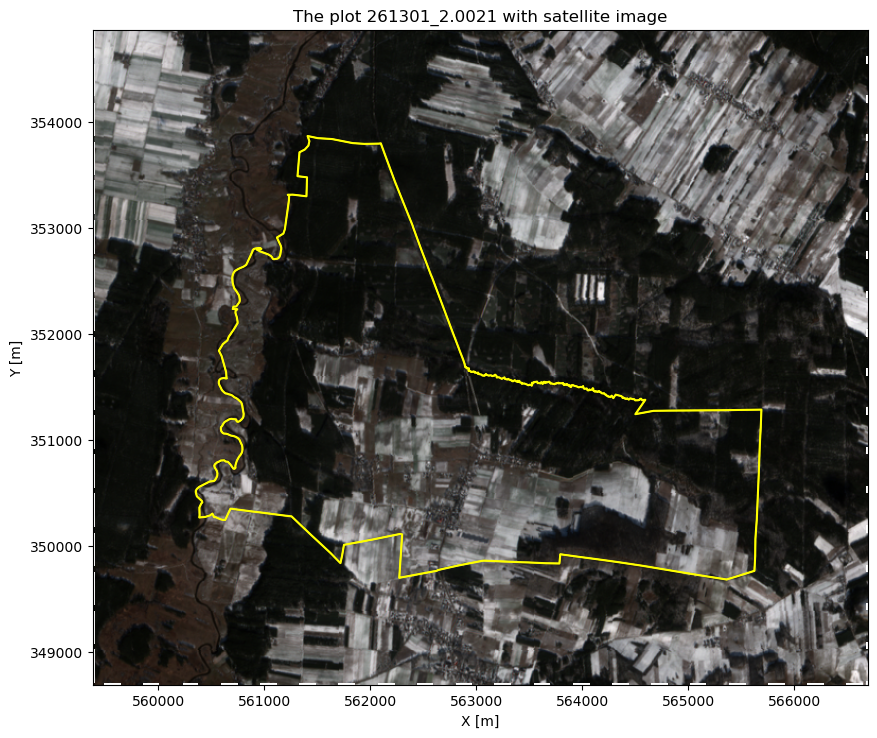

In [16]:
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(rgb, extent=extent, origin="lower")

# Plot boundry
gdf.boundary.plot(ax=ax, edgecolor="yellow", linewidth=1.5)
gdf.plot(ax=ax, facecolor="none", edgecolor="yellow")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("The plot 261301_2.0021 with satellite image")
plt.show()

In [17]:
## Mask: plot x raster
mask_valid = ~np.isnan(rgb).any(axis=2)
height, width, _ = rgb.shape
x_coords = np.linspace(extent[0] + h1["CELLSIZE"]/2, extent[1] - h1["CELLSIZE"]/2, width)
y_coords = np.linspace(extent[2] + h1["CELLSIZE"]/2, extent[3] - h1["CELLSIZE"]/2, height)
xx, yy = np.meshgrid(x_coords, y_coords)
points = np.vstack((xx.ravel(), yy.ravel())).T
points_geom = [Point(xy) for xy in points]
parcel_mask_flat = np.array([gdf.geometry.iloc[0].contains(pt) for pt in points_geom])
parcel_mask = parcel_mask_flat.reshape(height, width)
mask_in_parcel_flat = parcel_mask[mask_valid]
pixels_in_parcel = pixels[mask_in_parcel_flat]
labels_in_parcel = labels[mask_in_parcel_flat]

## Calculations limited to the plot
records = []
total_area = pixels_in_parcel.shape[0]

for i in range(n_clusters):
    cluster_pixels = pixels[labels == i]
    
    mean_rgb = cluster_pixels.mean(axis=0)
    brightness = mean_rgb.mean()
    area_px = cluster_pixels.shape[0]
    
    records.append({
        "Object": f"Cluster {i}",
        "R": mean_rgb[0],
        "G": mean_rgb[1],
        "B": mean_rgb[2],
        "Brightness": brightness,
        "Area_px": area_px,
        "Area_km2": area_px * PIXEL_AREA_M2 / 10**6,
        "Participation_%": 100 * area_px / total_area
    })

df_clusters = pd.DataFrame(records)
df_clusters = df_clusters.sort_values("Brightness", ascending=False)
df_clusters["Cumulative_Participation_%"] = df_clusters["Participation_%"].cumsum()

# Appending the line with the original image
orig_pixels = rgb[mask]
orig_mean_rgb = orig_pixels.mean(axis=0)
orig_brightness = orig_mean_rgb.mean()
orig_area_px = orig_pixels.shape[0]

df_original = pd.DataFrame([{
    "Object": "Original",
    "R": orig_mean_rgb[0],
    "G": orig_mean_rgb[1],
    "B": orig_mean_rgb[2],
    "Brightness": orig_brightness,
    "Area_px": orig_area_px,
    "Area_km2":orig_area_px * PIXEL_AREA_M2 / 10**6,
    "Participation_%": 100.0
}])

df = pd.concat([df_clusters, df_original], ignore_index=True)
df[["R", "G", "B", "Brigthness", "Participation_%", "Cumulative_Participation_%"]] = df[["R", "G", "B", "Brightness", "Participation_%", "Cumulative_Participation_%"]].round(2)

<a id="area-plot-table"></a>

In [18]:
display(df[["Object", "Brigthness", "Area_km2", "Participation_%", "Cumulative_Participation_%"]])

,Object,Brigthness,Area_km2,Participation_%,Cumulative_Participation_%
0,Cluster 3,0.67,3.3808,29.67,29.67
1,Cluster 2,0.48,5.3594,47.03,76.70
2,Cluster 0,0.32,6.3352,55.59,132.29
3,Cluster 4,0.17,9.8445,86.39,218.67
4,Cluster 1,0.06,20.0953,176.34,395.01
5,Original,NaN,45.0152,100.00,NaN


# Comments
- The `.dat` files contain the image geometry: NCOLS = 731, NROWS = 618; the header occupies the first 6 lines — this is currently hardcoded. The value 0 was treated as no-data, replaced with NaN and removed. The affected pixels are concentrated mainly along the image border, forming a pattern resembling blank regions.
- A grid-search procedure was used to find the optimal number of clusters, evaluating the inertia (within-cluster sum of squared distances to the centroid). The goal was to locate the "elbow point" beyond which increasing the number of clusters no longer yields a meaningful improvement in fit.
- Segmentation was performed with KMeans (K = 5). One selected cluster is highlighted <a href="#grid-image">in the visualisation </a>with the ❄️ symbol. It was chosen for having the highest mean pixel brightness — snow reflectance should be higher than that of its surroundings, so snow-covered areas are expected to appear brighter.
- Additional visual checks were made: whether the snow forms compact patches rather than scattered random pixels, and whether it is indeed white in the RGB image. The mean RGB values were also inspected, to verify that all three channels are comparable rather than one channel dominating and artificially inflating the overall brightness.
- Although a single cluster was selected for further analysis, the snow-covered area most likely spans several clusters (three in this example). These may represent different regimes, e.g.:
    - fresh snow (highest albedo — brightest),
    - old, settled snow,
    - partially melted or dirty snow mixed with mud.
- The table below shows the areas of the individual clusters. Assuming that snow corresponds to the three brightest clusters (clusters 0, 2 and 3 in this example), the snow-covered area amounts to 33.5%, i.e. approximately 15 km² - <a href="#area-table">as shown here</a>.
- The last code section attempts to integrate cadastral parcel 261301_2.0021 with the satellite image. The parcel's vector data was downloaded from geoportal.gov.pl as a point set in EPSG:2180. Fitting the parcel onto <a href="#plot-with-boundry">the image</a>  required flipping the raster (mirroring about the OX axis). Within the area bounded by the parcel, the snow coverage is 22.6%, corresponding to approximately 2.6 km² - <a href="#area-plot-table">as shown here</a>.
